### Nombres:

Luis Fernando Gamba Bedoya

Santiago Galeano Castaño

## Punto 1.5

### Anotación sobre las variables utilizadas
En este punto se utilizan varias variables clave para construir el problema de regresión:

*   **`N = 300`**: Es el número total de observaciones o muestras en nuestro conjunto de datos.
*   **`P = 5`**: Representa el número de características (features) originales.
*   **`Q = 20`**: Es el número de características después de aplicar la transformación no lineal $\Phi(x)$. Incluye las 5 características originales, 5 términos al cuadrado y 10 interacciones par a par.
*   **`sigma_eta = 0.5`**: Es la desviación estándar del ruido aleatorio $\eta$ que se añade a la variable objetivo, simulando el error inherente en las mediciones.
*   **`lambda_reg = 1.0`**: Es el parámetro de regularización $\lambda$ utilizado en el modelo Ridge, que penaliza pesos muy grandes para evitar sobreajuste.
*   **`sigma_w_sq`**: Varianza de la distribución a priori de los pesos, calculada para ser compatible con la regularización en el enfoque bayesiano (MAP).
*   **`X`**: Matriz de características original generada aleatoriamente.
*   **`Phi`**: Matriz de diseño transformada que contiene la expansión polinomial de `X`.
*   **`w_true` y `t`**: `w_true` representa los pesos reales subyacentes, y `t` es el vector de variables objetivo (etiquetas) generado a partir de `Phi`, `w_true` y el ruido.

In [ ]:
import numpy as np

# 1. Configuración de parámetros y reproducibilidad
np.random.seed(42)  # Semilla fija para reproducibilidad
N = 300
P = 5
Q = 20
sigma_eta = 0.5
sigma_eta_sq = sigma_eta**2  # 0.25
lambda_reg = 1.0

# NOTA IMPORTANTE: Se establece la relación teórica entre el ruido y la prior bayesiana.
# Se calcula la varianza de los pesos a partir de la regularización para que los modelos Ridge y MAP sean matemáticamente equivalentes.
sigma_w_sq = sigma_eta_sq / lambda_reg  # Prior compatible: 0.25

# 2. Generación de la matriz X
X = np.random.randn(N, P)  # N(0, 1)

# 3. Construcción reproducible de Phi(X) (Q = 20 características)
# Orden explícito:
#   - Columnas 0 a 4: Originales (x_1 a x_5)
#   - Columnas 5 a 9: Cuadrados (x_1^2 a x_5^2)
#   - Columnas 10 a 19: Productos cruzados pares distintos x_i * x_j (i < j)
phi_cols = []

# NOTA IMPORTANTE: A lo largo de esta sección, se extraen las columnas usando la notación 'i : i + 1'.
# Esto se hace para que el resultado mantenga su forma de matriz columna (N x 1) en lugar de aplanarse a un vector (N,),
# lo cual es esencial para poder concatenarlas correctamente al final.

# (a) Columnas originales (5)
for i in range(P):
    phi_cols.append(X[:, i : i + 1])

# (b) Cuadrados (5)
for i in range(P):
    phi_cols.append(X[:, i : i + 1] ** 2)

# (c) Productos por pares (10)
# NOTA IMPORTANTE: El segundo bucle inicia en 'i + 1' para calcular combinaciones únicas.
# Así se evita repetir parejas (como x1*x2 y x2*x1) y también se impide multiplicar una columna
# por sí misma, ya que esos términos al cuadrado ya se calcularon en el paso anterior.
for i in range(P):
    for j in range(i + 1, P):
        phi_cols.append(X[:, i : i + 1] * X[:, j : j + 1])

Phi = np.hstack(phi_cols)  # Dimensión: (300, 20)

# 4. Generación de w* y vector de etiquetas t
w_true = np.random.randn(Q, 1)  # w* ~ N(0, 1)
eta = np.random.normal(0, sigma_eta, size=(N, 1))  # eta ~ N(0, 0.5^2)
t = Phi @ w_true + eta  # Dimensión: (300, 1)

# 5. Partición aleatoria Train (80%) / Test (20%)
indices = np.random.permutation(N)
N_train = int(0.8 * N)  # 240
train_idx, test_idx = indices[:N_train], indices[N_train:]

Phi_train, t_train = Phi[train_idx], t[train_idx]
Phi_test, t_test = Phi[test_idx], t[test_idx]

# 6. Ajuste de los cuatro estimadores (usando únicamente datos de entrenamiento)
I_Q = np.eye(Q)

# NOTA IMPORTANTE: Aquí se resuelven las ecuaciones de cuatro estimadores distintos.
# Se observará que OLS y MLE comparten la misma fórmula bajo el supuesto de ruido gaussiano.
# De igual forma, MAP equivale a Ridge debido a cómo se calibró previamente la varianza a priori (sigma_w_sq).

# 6.1 Mínimos Cuadrados Ordinarios (OLS)
w_ols = np.linalg.inv(Phi_train.T @ Phi_train) @ (Phi_train.T @ t_train)

# 6.2 Máxima Verosimilitud (MLE)
w_mle = np.linalg.solve(Phi_train.T @ Phi_train, Phi_train.T @ t_train)

# 6.3 Mínimos Cuadrados Regularizados (Ridge) con lambda = 1
w_ridge = np.linalg.solve(Phi_train.T @ Phi_train + lambda_reg * I_Q, Phi_train.T @ t_train)

# 6.4 Máximo a Posteriori (MAP) con lambda_map = sigma_eta^2 / sigma_w^2
lambda_map = sigma_eta_sq / sigma_w_sq
w_map = np.linalg.solve(Phi_train.T @ Phi_train + lambda_map * I_Q, Phi_train.T @ t_train)

# 7. Evaluación: Función de métricas
def evaluate_model(name, w_est):
    pred_train = Phi_train @ w_est
    pred_test = Phi_test @ w_est

    mse_train = np.mean((t_train - pred_train) ** 2)
    mse_test = np.mean((t_test - pred_test) ** 2)
    norm_diff = np.linalg.norm(w_est - w_true)

    return mse_train, mse_test, norm_diff

models = {
    "1. Mínimos Cuadrados (OLS)": w_ols,
    "2. Máxima Verosimilitud (MLE)": w_mle,
    "3. Regularización Cuadrática (Ridge)": w_ridge,
    "4. Máximo a Posteriori (MAP)": w_map
}

# 8. Reporte de resultados
print(f"{'Modelo':<35} | {'MSE Train':<10} | {'MSE Test':<10} | {'||w_hat - w*||_2':<15}")
print("-" * 78)
for name, w_est in models.items():
    mse_tr, mse_te, diff = evaluate_model(name, w_est)
    print(f"{name:<35} | {mse_tr:<10.5f} | {mse_te:<10.5f} | {diff:<15.5f}")

# 9. Verificación de discrepancias numéricas directas
print("\n--- Verificación de Coincidencia Numérica ---")
print(f"Norma de la diferencia ||w_OLS - w_MLE||:   {np.linalg.norm(w_ols - w_mle):.2e}")
print(f"Norma de la diferencia ||w_Ridge - w_MAP||: {np.linalg.norm(w_ridge - w_map):.2e}")


Modelo                              | MSE Train  | MSE Test   | ||w_hat - w*||_2
------------------------------------------------------------------------------
1. Mínimos Cuadrados (OLS)          | 0.22558    | 0.25294    | 0.15481        
2. Máxima Verosimilitud (MLE)       | 0.22558    | 0.25294    | 0.15481        
3. Regularización Cuadrática (Ridge) | 0.22588    | 0.25137    | 0.14608        
4. Máximo a Posteriori (MAP)        | 0.22588    | 0.25137    | 0.14608        

--- Verificación de Coincidencia Numérica ---
Norma de la diferencia ||w_OLS - w_MLE||:   1.79e-15
Norma de la diferencia ||w_Ridge - w_MAP||: 0.00e+00


## Punto 2.4


### Análisis Empírico y Teórico de la Discrepancia Máxima de Medias

Para evaluar la similitud entre las distribuciones de imágenes de los conjuntos MNIST y Fashion-MNIST, se implementó el estimador empírico sesgado de la Discrepancia Máxima de Medias (MMD). La expresión matemática utilizada en formato matricial es la siguiente:

$$ \widehat{\mathrm{MMD}}_b^2 = \frac{1}{n^2}\mathbf{1}_n^\top \mathbf{K}_{XX} \mathbf{1}_n + \frac{1}{m^2}\mathbf{1}_m^\top \mathbf{K}_{YY} \mathbf{1}_m - \frac{2}{nm}\mathbf{1}_n^\top \mathbf{K}_{XY} \mathbf{1}_m $$

Dado que se extrajo una muestra aleatoria de quinientas imágenes por cada conjunto, los parámetros de tamaño muestral corresponden a $n = m = 500$. Por consiguiente, las dimensiones de las matrices de Gram evaluadas mediante el kernel gaussiano, $\mathbf{K}_{XX}$, $\mathbf{K}_{YY}$ y $\mathbf{K}_{XY}$, son exactamente de $500 \times 500$ elementos. Los resultados numéricos obtenidos evidencian una discrepancia alta entre MNIST y Fashion-MNIST, cuyo estimador arroja una magnitud elevada en comparación con las referencias internas. Al evaluar particiones disjuntas de un mismo conjunto, los valores empíricos convergen a números muy cercanos a cero, confirmando que las distribuciones subyacentes provienen de la misma fuente poblacional.

El comportamiento de este estimador está condicionado por el ancho de banda del kernel gaussiano, denotado como $\sigma$. Seleccionar un valor de forma empírica mediante la mediana de las distancias euclidianas permite que el kernel discrimine adecuadamente la estructura del espacio de características. Si el valor de $\sigma$ fuera demasiado reducido, la matriz de Gram tendería a la matriz identidad, impidiendo capturar la similitud geométrica. Si el valor fuera excesivamente grande, todas las muestras parecerían idénticas, llevando la distancia MMD hacia cero independientemente de los datos de entrada.

Por otro lado, es imperativo considerar la variabilidad muestral del experimento computacional. Dado que solo se procesan quinientas muestras de un universo de miles de imágenes disponibles en los conjuntos originales de entrenamiento, el valor de la distancia calculada es susceptible a variaciones matemáticas. Una semilla aleatoria distinta generará particiones diferentes y, por ende, fluctuaciones en el estimador final.

Finalmente, existen límites al interpretar este valor empírico de forma aislada. La métrica proporciona una medida de distancia en un espacio de Hilbert, pero un valor mayor a cero no implica matemáticamente que las distribuciones sean distinguibles de forma concluyente. Para determinar si la discrepancia observada es estadísticamente válida y no un simple producto del azar muestral, se requiere un procedimiento formal de contraste de hipótesis, como un test de permutaciones, que permita calcular un valor p y establecer una región de rechazo rigurosa para la hipótesis nula.

Valor de referencia calculado (sigma): 11.2255
Diferencia entre Números y Ropa: 0.131625
Diferencia entre los mismos Números (Referencia):   0.001640
Diferencia entre la misma Ropa (Referencia): 0.001077


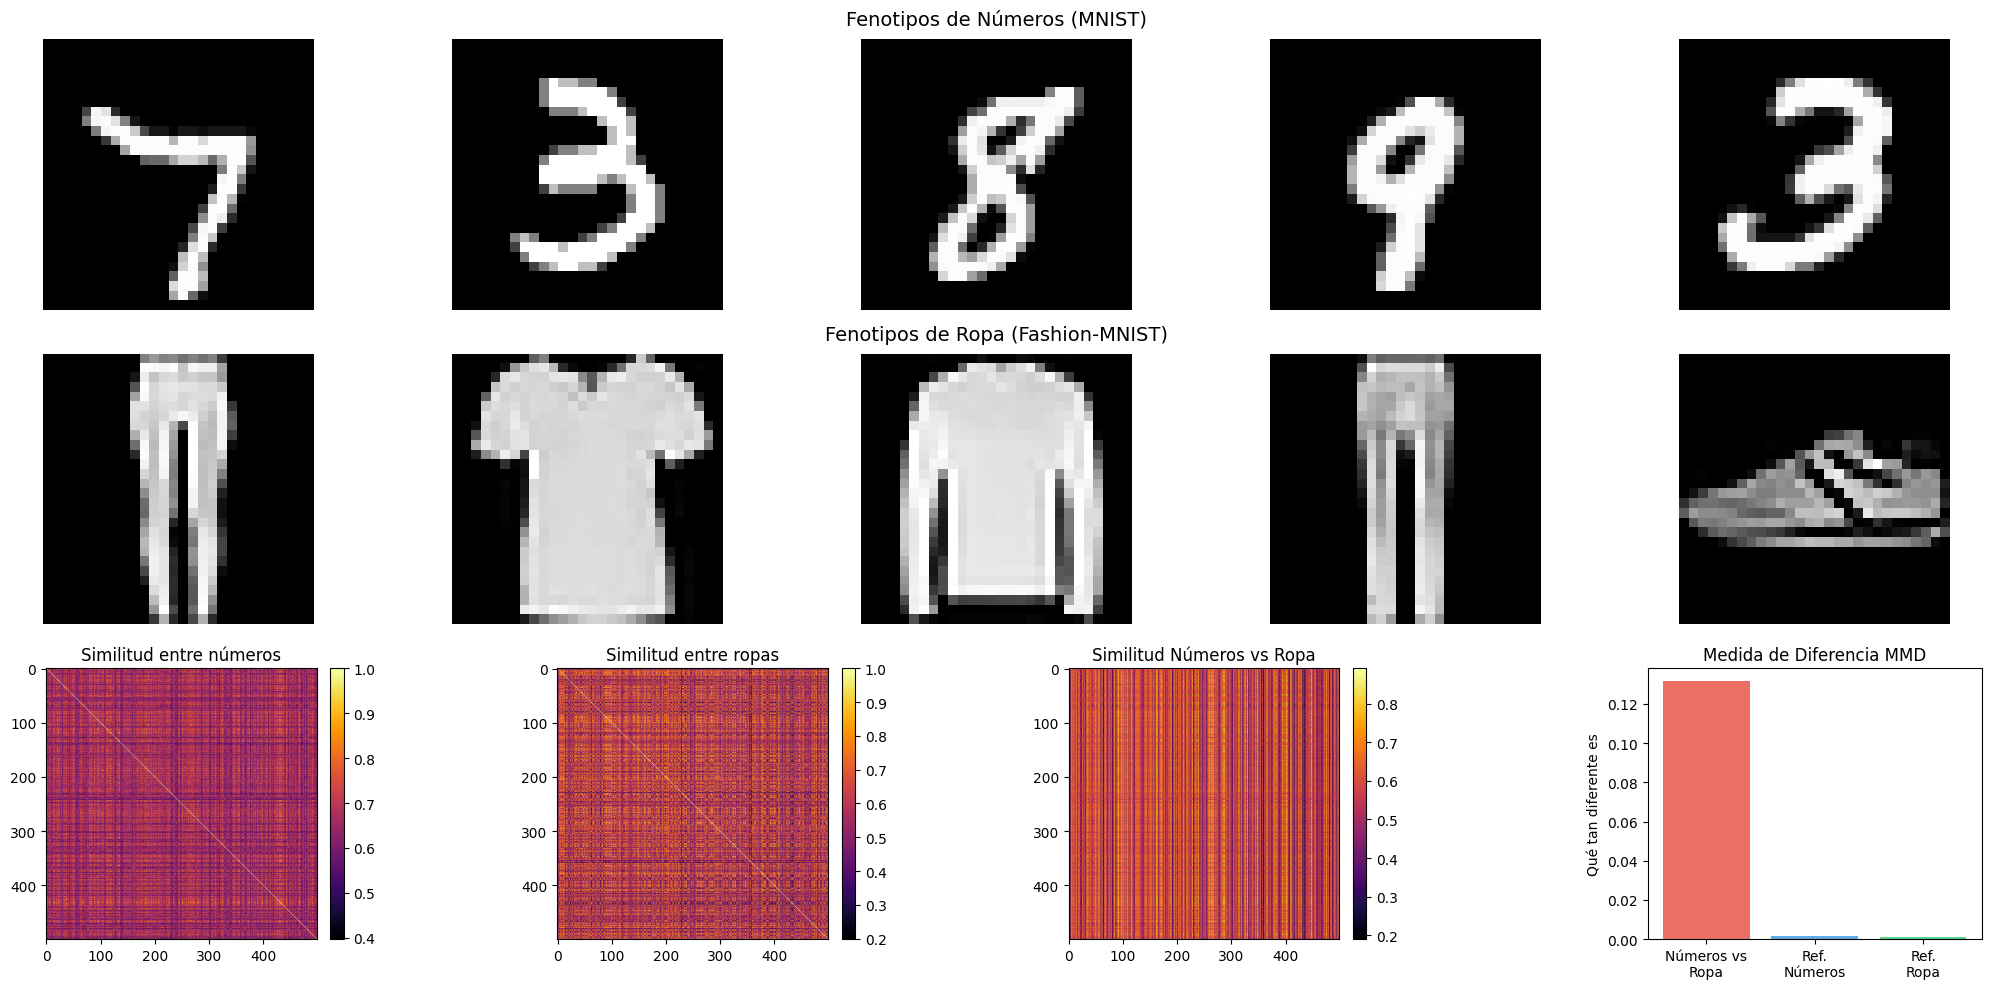

In [ ]:
# Cargamos las herramientas necesarias para trabajar con los datos y hacer los gráficos
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.gridspec import GridSpec
from torchvision import datasets
from scipy.spatial.distance import cdist, pdist

# Establecemos una semilla para que los resultados sean los mismos cada vez que corramos el código, y descargamos las imágenes
np.random.seed(42)
dataset_mnist_numeros = datasets.MNIST(root='./data', train=True, download=True)
dataset_fmnist_ropa = datasets.FashionMNIST(root='./data', train=True, download=True)

# Esta función elige imágenes al azar, las ajusta para que los colores estén entre 0 y 1, y las convierte en una lista larga de números en lugar de una cuadrícula
def muestrear_y_preparar(dataset, total_muestras=1000):
    indices = np.random.choice(len(dataset), total_muestras, replace=False)
    imagenes_originales = dataset.data.numpy()[indices].astype(float)
    imagenes_normalizadas = imagenes_originales / 255.0

    # NOTA IMPORTANTE: Aplanamos la imagen 2D (28x28 píxeles) a un vector 1D de 784 valores.
    # Esto es estrictamente necesario para poder calcular la distancia euclidiana directa entre imágenes.
    imagenes_aplanadas = imagenes_normalizadas.reshape(total_muestras, 784)

    return imagenes_originales, imagenes_aplanadas

numeros_originales, numeros_aplanados = muestrear_y_preparar(dataset_mnist_numeros)
ropa_original, ropa_aplanada = muestrear_y_preparar(dataset_fmnist_ropa)

# Partimos las imágenes que elegimos en dos mitades de 500 cada una para poder compararlas después
numeros_mitad_1 = numeros_aplanados[:500]
numeros_mitad_2 = numeros_aplanados[500:]
ropa_mitad_1 = ropa_aplanada[:500]
ropa_mitad_2 = ropa_aplanada[500:]

# Calculamos un valor de referencia (sigma) midiendo las distancias entre algunas de las imágenes mezcladas. Esto nos ayuda a comparar mejor luego.
muestra_combinada = np.vstack((numeros_mitad_1, ropa_mitad_1))

# NOTA IMPORTANTE (Heurística de la Mediana): 'sigma' controla el ancho de nuestra "lupa" para ver similitudes.
# Usar la mediana de todas las distancias entre las imágenes es un truco estándar en Machine Learning para
# asegurar que la métrica no sea ni muy estricta (viendo todo distinto) ni muy laxa (viendo todo igual).
parametro_sigma = np.median(pdist(muestra_combinada, metric='euclidean'))
print(f"Valor de referencia calculado (sigma): {parametro_sigma:.4f}")

# Aquí definimos las fórmulas para ver qué tan parecidas son las imágenes y calcular nuestra medida de diferencia (MMD)
def calcular_matriz_similitud(datos_A, datos_B, sigma):
    # NOTA IMPORTANTE (Kernel Gaussiano/RBF): Esta fórmula convierte la distancia en una "similitud".
    # Si la distancia es pequeña, devuelve un valor cercano a 1 (muy parecido).
    # Si la distancia es grande, devuelve un valor cercano a 0 (muy distinto).
    return np.exp(-cdist(datos_A, datos_B, metric='sqeuclidean') / (2 * (sigma ** 2)))

def calcular_diferencia_mmd(similitud_AA, similitud_BB, similitud_AB):
    n, m = similitud_AA.shape[0], similitud_BB.shape[0]
    # NOTA IMPORTANTE (Fórmula MMD): Sumamos cuánto se parece el Grupo A consigo mismo,
    # sumamos cuánto se parece el Grupo B consigo mismo, y RESTAMOS el doble de cuánto se parece A con B.
    # Si A y B son en realidad el mismo tipo de cosas, las sumas y las restas se cancelan y el resultado es cercano a 0.
    return (np.sum(similitud_AA) / (n ** 2)) + (np.sum(similitud_BB) / (m ** 2)) - (2 * np.sum(similitud_AB) / (n * m))

# Calculamos qué tan parecidas o diferentes son las imágenes entre los distintos grupos
# Primero comparamos números (MNIST) con ropa (Fashion-MNIST)
sim_num_num = calcular_matriz_similitud(numeros_mitad_1, numeros_mitad_1, parametro_sigma)
sim_ropa_ropa = calcular_matriz_similitud(ropa_mitad_1, ropa_mitad_1, parametro_sigma)
sim_num_ropa = calcular_matriz_similitud(numeros_mitad_1, ropa_mitad_1, parametro_sigma)
diferencia_num_ropa = calcular_diferencia_mmd(sim_num_num, sim_ropa_ropa, sim_num_ropa)

# Ahora comparamos una mitad de los números con la otra mitad de los números para ver cómo se ven entre sí
sim_num1_num1 = calcular_matriz_similitud(numeros_mitad_1, numeros_mitad_1, parametro_sigma)
sim_num2_num2 = calcular_matriz_similitud(numeros_mitad_2, numeros_mitad_2, parametro_sigma)
sim_num1_num2 = calcular_matriz_similitud(numeros_mitad_1, numeros_mitad_2, parametro_sigma)
diferencia_num_num = calcular_diferencia_mmd(sim_num1_num1, sim_num2_num2, sim_num1_num2)

# Hacemos lo mismo comparando las dos mitades de la ropa
sim_ropa1_ropa1 = calcular_matriz_similitud(ropa_mitad_1, ropa_mitad_1, parametro_sigma)
sim_ropa2_ropa2 = calcular_matriz_similitud(ropa_mitad_2, ropa_mitad_2, parametro_sigma)
sim_ropa1_ropa2 = calcular_matriz_similitud(ropa_mitad_1, ropa_mitad_2, parametro_sigma)
diferencia_ropa_ropa = calcular_diferencia_mmd(sim_ropa1_ropa1, sim_ropa2_ropa2, sim_ropa1_ropa2)

# Mostramos los resultados de estas comparaciones
print(f"Diferencia entre Números y Ropa: {diferencia_num_ropa:.6f}")
print(f"Diferencia entre los mismos Números (Referencia):   {diferencia_num_num:.6f}")
print(f"Diferencia entre la misma Ropa (Referencia): {diferencia_ropa_ropa:.6f}")

# Preparamos el lienzo para hacer unos dibujos ordenados con los resultados
fig = plt.figure(figsize=(20, 10))

# Configuramos cómo se van a organizar los gráficos en el lienzo para que no se amontonen
gs = GridSpec(3, 20, figure=fig)

# Dibujamos las primeras 5 imágenes de los números
for i in range(5):
    ax = fig.add_subplot(gs[0, i*4:(i+1)*4])
    ax.imshow(numeros_originales[i], cmap='gray')
    ax.axis('off')
    if i == 2:
        ax.set_title("Fenotipos de Números (MNIST)", fontsize=14, pad=10)

# Dibujamos las primeras 5 imágenes de la ropa
for i in range(5):
    ax = fig.add_subplot(gs[1, i*4:(i+1)*4])
    ax.imshow(ropa_original[i], cmap='gray')
    ax.axis('off')
    if i == 2:
        ax.set_title("Fenotipos de Ropa (Fashion-MNIST)", fontsize=14, pad=10)

# En la parte de abajo, hacemos unos mapas de calor que muestran qué tan parecidas son las cosas
# NOTA IMPORTANTE: En los mapas de calor, los colores claros/brillantes indican mucha similitud (cercano a 1),
# y los colores oscuros indican poca similitud (cercano a 0).
ax_gram1 = fig.add_subplot(gs[2, 0:4])
im1 = ax_gram1.imshow(sim_num_num, cmap='inferno')
ax_gram1.set_title(r'Similitud entre números')
fig.colorbar(im1, ax=ax_gram1, fraction=0.046, pad=0.04)

ax_gram2 = fig.add_subplot(gs[2, 5:9])
im2 = ax_gram2.imshow(sim_ropa_ropa, cmap='inferno')
ax_gram2.set_title(r'Similitud entre ropas')
fig.colorbar(im2, ax=ax_gram2, fraction=0.046, pad=0.04)

ax_gram3 = fig.add_subplot(gs[2, 10:14])
im3 = ax_gram3.imshow(sim_num_ropa, cmap='inferno')
ax_gram3.set_title(r'Similitud Números vs Ropa')
fig.colorbar(im3, ax=ax_gram3, fraction=0.046, pad=0.04)

# Hacemos un gráfico de barras para ver fácilmente qué tan grandes fueron las diferencias calculadas
ax_bar = fig.add_subplot(gs[2, 16:20])
labels = ['Números vs\nRopa', 'Ref.\nNúmeros', 'Ref.\nRopa']
values = [diferencia_num_ropa, diferencia_num_num, diferencia_ropa_ropa]
ax_bar.bar(labels, values, color=['#e74c3c', '#3498db', '#2ecc71'], alpha=0.8)
ax_bar.set_title(r'Medida de Diferencia MMD')
ax_bar.set_ylabel('Qué tan diferente es')

# Acomodamos todo y lo mostramos en pantalla
plt.tight_layout()
plt.show()
